In [38]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

In [39]:
df = pd.read_csv("results_mmap.csv")
METRIC = "real"
CONFIDENCE = 0.95

In [40]:
stats_rows = []
for mode, group in df.groupby("mode"):
    sample = group[METRIC].to_numpy()
    n = len(sample)
    mean = sample.mean()
    s = sample.std(ddof=1)
    sem = stats.sem(sample)
    if sem > 0:
        ci_low, ci_high = stats.t.interval(CONFIDENCE, df=n - 1, loc=mean, scale=sem)
    else:
        ci_low, ci_high = mean, mean
    stats_rows.append(
        {
            "mode": mode,
            "n": n,
            "mean": mean,
            "std": s,
            "ci_low": ci_low,
            "ci_high": ci_high,
            "ci_halfwidth": mean - ci_low,
        }
    )

summary = pd.DataFrame(stats_rows)

In [41]:
summary

,mode,n,mean,std,ci_low,ci_high,ci_halfwidth
0,read,100,0.05843,0.005809,0.057277,0.059583,0.001153
1,write,100,0.07244,0.011323,0.070193,0.074687,0.002247


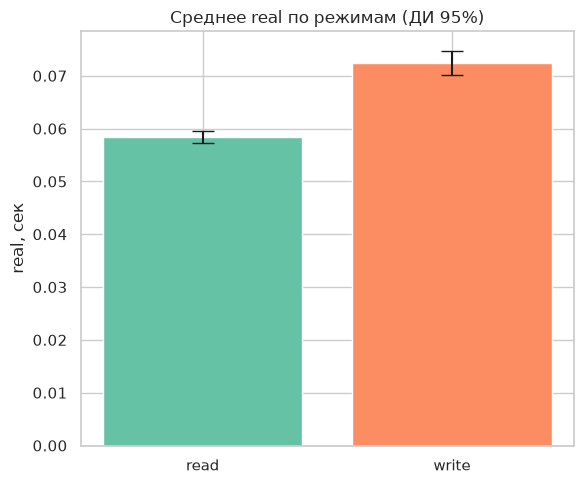

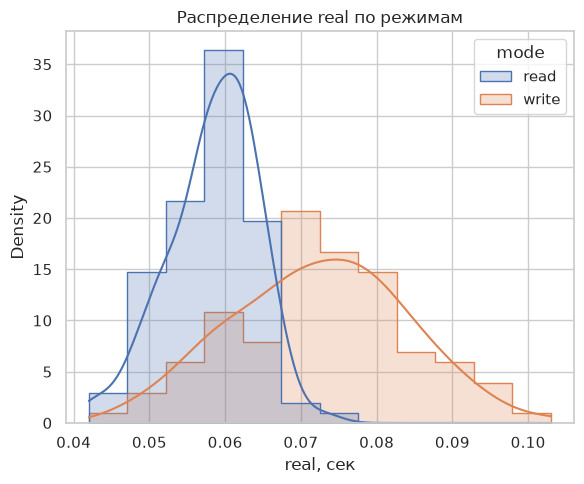

In [42]:
sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(6, 5))
ax.bar(
    summary["mode"],
    summary["mean"],
    yerr=summary["ci_halfwidth"],
    capsize=8,
    color=sns.color_palette("Set2"),
)
ax.set_ylabel(f"{METRIC}, сек")
ax.set_title(f"Среднее {METRIC} по режимам (ДИ {int(CONFIDENCE * 100)}%)")
fig.tight_layout()

fig2, ax2 = plt.subplots(figsize=(6, 5))
sns.histplot(data=df, x=METRIC, hue="mode", kde=True, stat="density", element="step", ax=ax2)
ax2.set_xlabel(f"{METRIC}, сек")
ax2.set_title(f"Распределение {METRIC} по режимам")
fig2.tight_layout()

plt.show()